# MediCheck-GPT: run the full flow on Colab (v2)
Runtime → Change runtime type → **T4 GPU**. Run top to bottom.



## 0. Setup: GPU, code, data

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv   # confirm the T4 is attached

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
from google.colab import drive
drive.mount('/content/drive')                     # the raw CMS file lives in my Drive
ROOT = '/content/drive/MyDrive/build-transformer'   # same folder as 01_data.ipynb

Mounted at /content/drive


In [3]:
!rm -rf /content/medicheck-gpt                       # never run an old copy of the code
!git clone https://github.com/cece15/medicheck-gpt.git /content/medicheck-gpt
%cd /content/medicheck-gpt
!pip install -q -r requirements.txt
# data and checkpoints live in Drive, so a Colab disconnect loses nothing: rerun from the cell that stopped
!mkdir -p "$ROOT/medicheck/data" "$ROOT/medicheck/checkpoints"
!ln -sfn "$ROOT/medicheck/data" data && ln -sfn "$ROOT/medicheck/checkpoints" checkpoints && ls -l
!git log --oneline -1                               # should NOT say 'Created using Colab'

Cloning into '/content/medicheck-gpt'...
remote: Enumerating objects: 86, done.
remote: Counting objects: 100% (86/86), done.
remote: Compressing objects: 100% (52/52), done.
remote: Total 86 (delta 53), reused 56 (delta 28), pack-reused 0 (from 0)
Receiving objects: 100% (86/86), 94.91 KiB | 803.00 KiB/s, done.
Resolving deltas: 100% (53/53), done.
/content/medicheck-gpt
total 60
lrwxrwxrwx 1 root root    62 Nov 14 21:33 checkpoints -> /content/drive/MyDrive/build-transformer/medicheck/checkpoints
lrwxrwxrwx 1 root root    55 Nov 14 21:33 data -> /content/drive/MyDrive/build-transformer/medicheck/data
-rwxr-xr-x 1 root root 14770 Nov 14 21:33 gpt.py
drwxr-xr-x 2 root root  4096 Nov 14 21:33 notebooks
-rw-r--r-- 1 root root 13969 Nov 14 21:33 README.md
-rw-r--r-- 1 root root   140 Nov 14 21:33 requirements.txt
drwxr-xr-x 2 root root  4096 Nov 14 21:33 src
-rw-r--r-- 1 root root 10435 Nov 14 21:33 WALKTHROUGH.md
2dd182d (HEAD -> main, origin/main, origin/HEAD) Faster AUC (rank-based) so

## 1. Data: CSV → one sentence per row → split by hospital

In [4]:
import os
if not os.path.exists('data/processed/test.txt'):
    !python gpt.py --input "$ROOT/data/raw/MUP_INP_RY26_P03_V10_DY24_PrvSvc.CSV" --prepare data/processed
!head -c 600 data/processed/train.txt


Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 291 (HEART FAILURE AND SHOCK WITH MCC) for 20 discharges: covered charges $19134, total payment $9134, Medicare payment $7828.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 871 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITH MCC) for 53 discharges: covered charges $28663, total payment $12681, Medicare payment $10761.
Corewell Health Zeeland Hospital in Zeeland, MI billed DRG 872 (SEPTICEMIA OR SEVERE SEPSIS WITHOUT MV >96 HOURS WITHOUT MCC) for 21 discharges: covered charges $19285, total payment $8101, Medicare p

## 2. Baseline: bigram (one character of memory)

In [5]:
if not os.path.exists('checkpoints/bigram.pth'):
    !python gpt.py --input data/processed --train checkpoints/bigram.pth --model bigram --context_size 8 --lr 1e-2 --steps 3000

## 3. Transformer: 4 layers, 4 heads, 128-dim, context 271 (one full record)
Cosine LR with warmup, weight decay, early stopping. First run (3 Nov) overfit after ~1,500 steps, so these guards matter.

In [6]:
if not os.path.exists('checkpoints/gpt.pth'):
    !python gpt.py --input data/processed --train checkpoints/gpt.pth --steps 10000 --eval_every 500 --patience 4

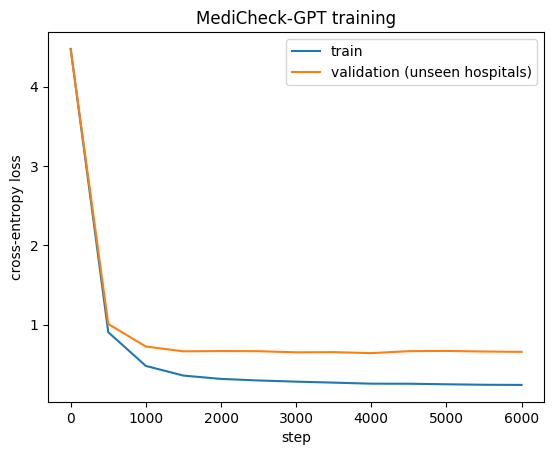

In [7]:
# Loss curve for the slides
import json, matplotlib.pyplot as plt
h = json.load(open('checkpoints/gpt_history.json'))
plt.plot([r['step'] for r in h], [r['train'] for r in h], label='train')
plt.plot([r['step'] for r in h], [r['val'] for r in h], label='validation (unseen hospitals)')
plt.xlabel('step'); plt.ylabel('cross-entropy loss'); plt.legend(); plt.title('MediCheck-GPT training')
plt.savefig('checkpoints/loss_curve.png', dpi=200, bbox_inches='tight'); plt.show()

## 3a. Hyperparameter comparison (Week 7: fine-tuning and hyperparameter tuning)
Same data, same seed, same early stopping. Only the model size and dropout change. About 15 minutes.

In [8]:
# smaller and larger than the base model (base = 4 layers, 4 heads, 128-dim, already trained above)
if not os.path.exists('checkpoints/gpt_large.pth'):
    !python gpt.py --input data/processed --train checkpoints/gpt_small.pth --n_layer 2 --n_head 2 --n_embd 64 --steps 6000
    !python gpt.py --input data/processed --train checkpoints/gpt_large.pth --n_layer 6 --n_head 6 --n_embd 192 --dropout 0.2 --steps 6000

In [9]:
# one table for the slides: which size generalizes best to unseen hospitals?
import math, torch, pandas as pd
from src.model import build, count_params
rows = []
for name in ['gpt_small', 'gpt', 'gpt_large']:
    ck = torch.load(f'checkpoints/{name}.pth', map_location='cpu')
    best = min(ck['history'], key=lambda r: r['val'])            # the checkpoint holds the best evaluation
    rows.append({'model': name, **{k: ck['config'][k] for k in ['n_layer', 'n_head', 'n_embd', 'dropout']},
                 'parameters': count_params(build(ck['kind'], **ck['config'])),
                 'best_step': best['step'], 'best_val_loss': round(best['val'], 4),
                 'val_perplexity': round(math.exp(best['val']), 3), 'seconds': best['seconds']})
pd.DataFrame(rows)

,model,n_layer,n_head,n_embd,dropout,parameters,best_step,best_val_loss,val_perplexity,seconds
0,gpt_small,2,2,64,0.1,126989,3500,0.7434,2.103,77
1,gpt,4,4,128,0.1,846285,4000,0.6403,1.897,331
2,gpt_large,6,6,192,0.2,2747789,1500,0.6341,1.885,302


## 3b. Kacper's recommendation: an LLM teacher writes plain-English descriptions (v2)
Run 1 showed the teacher invents numbers (14%) and, worse, attaches real numbers to the wrong label. v2 gives the LLM each fact as a full phrase and one example, rejects sentences with invented or mislabeled numbers, and gives each rejected record one retry. About 25–30 minutes.

In [10]:
import os
if not os.path.exists('data/described_v2/test.txt'):       # the teacher is the slow step: never run it twice
    !python gpt.py --input data/processed --teacher data/described_v2 --limit 5000
print(open('data/described_v2/teacher_report.json').read())
!head -c 1200 data/described_v2/train.txt

device: cuda
config.json: 100% 660/660 [00:00<00:00, 3.32MB/s]
tokenizer_config.json: 100% 7.30k/7.30k [00:00<00:00, 26.7MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 69.3MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 122MB/s]
tokenizer.json: 100% 7.03M/7.03M [00:00<00:00, 146MB/s]

model.safetensors: downloading bytes:   0% 0.00/3.09G [00:00<?, ?B/s]
model.safetensors: downloading bytes:   2% 51.6M/3.09G [00:01<00:39, 76.9MB/s, 3.36MB/s  ]
model.safetensors: downloading bytes:   3% 82.2M/3.09G [00:01<00:28, 105MB/s, 6.19MB/s  ] 
model.safetensors: downloading bytes:   8% 244M/3.09G [00:02<00:14, 192MB/s, 20.6MB/s  ]
model.safetensors: downloading bytes:   9% 265M/3.09G [00:02<00:17, 158MB/s, 23.2MB/s  ]
model.safetensors: reconstructing file:   5% 163M/3.09G [00:02<00:32, 89.2MB/s, 12.9MB/s  ]
model.safetensors: downloading bytes:   9% 291M/3.09G [00:02<00:19, 146MB/s, 24.6MB/s  ]
model.safetensors: downloading bytes:  10% 314M/3.09G [00:02<00:20, 136MB/s, 26.6MB/s  ]
model.safet

## 3c. Student v2: pre-train, then fine-tune (Lecture 6–7)
Run 1 trained from scratch on random windows; it learned the teacher's style but ignored the record. v2 starts from the record model (`gpt.pth`, which already knows records) and fine-tunes on whole examples with the loss on the explanation only. Validation loss here is explanation-only, so it is not comparable with run 1's.

In [11]:
!python gpt.py --input data/described_v2 --train checkpoints/explain_v2.pth --init_from checkpoints/gpt.pth --steps 4000 --eval_every 250 --patience 4

device: cuda
context_size 271 -> 595 so one full example fits
started from checkpoints/gpt.pth: 94 weight tensors copied
gpt (explain): 0.89M parameters | vocab 81 | 3,328 train / 594 val examples
step      0 | train 5.5192 | val 5.8869 | val_perplexity 360.302 | val_rougeL 0.016 | val_numbers_faithful 0.000 | 37s
step    250 | train 0.8555 | val 1.1221 | val_perplexity 3.071 | val_rougeL 0.184 | val_numbers_faithful 0.000 | 100s
step    500 | train 0.4817 | val 0.7849 | val_perplexity 2.192 | val_rougeL 0.257 | val_numbers_faithful 0.000 | 161s
step    750 | train 0.3807 | val 0.7177 | val_perplexity 2.050 | val_rougeL 0.281 | val_numbers_faithful 0.000 | 223s
step   1000 | train 0.3240 | val 0.6720 | val_perplexity 1.958 | val_rougeL 0.316 | val_numbers_faithful 0.000 | 287s
step   1250 | train 0.2988 | val 0.6643 | val_perplexity 1.943 | val_rougeL 0.273 | val_numbers_faithful 0.000 | 348s
step   1500 | train 0.2758 | val 0.6467 | val_perplexity 1.909 | val_rougeL 0.339 | val_number

In [12]:
# pass the record as a Python argument: records contain '$', which the shell would eat
import subprocess
rec = open('data/processed/test.txt').read().split('\n')[1]
print('record :', rec)
print(subprocess.run(['python', 'gpt.py', '--eval', 'checkpoints/explain_v2.pth', '--prompt', rec, '--n', '3'],
                     capture_output=True, text=True).stdout)

record : Munson Healthcare Grayling Hospital in Grayling, MI billed DRG 177 (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681.
device: cuda
Munson Healthcare's Cadillac Hospital treated 62 Medicare patients with cardiac arrhythmia and conduction disorders, averaging a bill of $30,510 but receiving $13,089 in total payments, with Medicare covering 88% of the cost. 

Munson Healthcare Otsego Memorial Hospital treated 15 Medicare patients with circulatory disorders including cardiac catheterization but excluding $30,993 in total payments, with Medicare covering 82% of those payments. 

Munson Healthcare Otsego Memorial Hospital in Gaylord, MI treated 12 Medicare patients with hip and femur procedures except major joints, averaging a bill of $27,180 but receiving $11,811 in total payments, with Medicare covering 84% of the amount. 




## 4. Generate

In [13]:
!python gpt.py --eval checkpoints/gpt.pth --n 3
!python gpt.py --eval checkpoints/gpt.pth --n 2 --prompt "Trinity Health Livonia Hospital in Livonia, MI billed DRG "

device: cuda
Mercy Health - Springfield Regional Medical Center in Sandusky, OH billed DRG 481 (HIP AND FEMUR PROCEDURES EXCEPT MAJOR JOINT WITH CC) for 12 discharges: covered charges $64359, total payment $13944, Medicare payment $9877. 

Mercy Health St Vincent Medical Center in Toledo, OH billed DRG 064 (INTRACRANIAL HEMORRHAGE OR CEREBRAL INFARCTION WITH MCC) for 14 discharges: covered charges $301298, total payment $9381, Medicare payment $7730. 

Corewell Health Grand Rapids Hospitals Butterworth in Grand Rapids, MI billed DRG 278 (OTHER CIRCULATORY SYSTEM DIAGNOSES WITH MCC) for 11 discharges: covered charges $5606, total payment $12384, Medicare payment $1816. 

device: cuda
Trinity Health Livonia Hospital in Livonia, MI billed DRG 982 (EXTENSIVE O.R. PROCEDURES UNRELATED TO PRINCIPAL DIAGNOSIS WITH MCC) for 35 discharges: covered charges $150454, total payment $110715, Medicare payment $13081. 

Trinity Health Livonia Hospital in Livonia, MI billed DRG 538 (FRACTURE, SPRAIN, S

## 5. Evaluate: perplexity, token accuracy, ROUGE-L (+ BLEU, BERTScore), record validity

In [14]:
!python gpt.py --input data/processed --evaluate checkpoints/bigram.pth
!python gpt.py --input data/processed --evaluate checkpoints/gpt.pth --hf_metrics
!python gpt.py --input data/described_v2 --evaluate checkpoints/explain_v2.pth --hf_metrics

device: cuda
{
 "model": "bigram",
 "test_perplexity": 8.64,
 "test_token_accuracy": 0.329,
 "rougeL": 0.004,
 "validity_generated": {
  "parses": 0.0,
  "drg_matches_description": 0.0,
  "medicare_le_total_payment": 0.0,
  "total_payment_le_charges": 0.0,
  "known_hospital_in_right_place": null
 },
 "validity_real_test_records": {
  "parses": 1.0,
  "drg_matches_description": 0.997,
  "medicare_le_total_payment": 1.0,
  "total_payment_le_charges": 1.0,
  "known_hospital_in_right_place": null
 }
}

example completion
  real : (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681. 
  model: Hoschin $131118 dids Cichalledicharergent ch MCAG palRERORES CCHent 14834507.
device: cuda
config.json: 100% 482/482 [00:00<00:00, 1.85MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 95.5kB/s]
vocab.json: 100% 899k/899k [00:00<00:00, 10.1MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 25.0MB/s]
tokenizer.j

## 6. Flag silent errors
Three scores: raw surprise; surprise after the hospital name; and the likelihood ratio against the bigram (Ren et al., 2019). AUC 0.5 = chance; the 95% interval is for the last score.

In [15]:
!python gpt.py --input data/processed --flag checkpoints/gpt.pth --background checkpoints/bigram.pth
!python gpt.py --input data/processed --flag checkpoints/gpt_large.pth --background checkpoints/bigram.pth

device: cuda
error type            n    auc_raw   auc_cond  auc_ratio          95% CI
drg_mismatch        500      0.677      0.521      0.525   (0.49, 0.557)
wrong_city          500      0.208      0.139      0.147  (0.125, 0.172)
payments_swapped    500      0.529      0.507      0.514  (0.478, 0.548)
extra_digit         500      0.542      0.513      0.523  (0.488, 0.555)

example planted errors:
  drg_mismatch: Munson Healthcare Grayling Hospital in Grayling, MI billed DRG 177 (O.R. PROCEDURES FOR OBESITY WITH CC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681.
  wrong_city: Munson Healthcare Grayling Hospital in Gaylord, MI billed DRG 177 (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 27 discharges: covered charges $37016, total payment $15466, Medicare payment $14681.
  payments_swapped: Munson Healthcare Grayling Hospital in Grayling, MI billed DRG 177 (RESPIRATORY INFECTIONS AND INFLAMMATIONS WITH MCC) for 27 discharges: covere

## 6b. Demo file for Tuesday: five real test records and five with planted errors, shuffled

In [16]:
import random, sys
sys.path.insert(0, '.')
from src.flag import corrupt, KINDS
from src.data import parse
test = [r for r in open('data/processed/test.txt').read().split('\n') if parse(r)]
train = [r for r in open('data/processed/train.txt').read().split('\n') if parse(r)]
drg = {parse(r)['drg']: parse(r)['desc'] for r in train}
cities = {}
for r in train:
    f = parse(r); cities.setdefault(f['state'], set()).add(f['city'])
cities = {s: sorted(c) for s, c in cities.items()}
rng = random.Random(7)
clean = rng.sample(test, 5)
planted = [corrupt(r, KINDS[i % 4], drg, cities, rng) for i, r in enumerate(rng.sample(test, 5))]
demo = clean + [p for p in planted if p]
rng.shuffle(demo)
open('data/suspicious.txt', 'w').write('\n'.join(demo) + '\n')
open('data/suspicious_answer_key.txt', 'w').write('\n'.join(('PLANTED  ' if r in planted else 'clean    ') + r for r in demo))
!python gpt.py --flag checkpoints/gpt.pth --background checkpoints/bigram.pth --flag_file data/suspicious.txt
!cat data/suspicious_answer_key.txt

device: cuda
  3.51  Mclaren Macomb in Mount Clemens, MI billed DRG 314 (OTHER CIRCULATORY SYSTEM DIAGNOSES WITH MCC) for 16 discharges: covered charges $37052, total payment $16862, Medicare payment $13812.
  3.20  Genesis Hospital in Zanesville, OH billed DRG 813 (COAGULATION DISORDERS) for 17 discharges: covered charges $33838, total payment $12962, Medicare payment $11906.
  1.35  Henry Ford Health Genesys Hospital in Grand Blanc, MI billed DRG 641 (MISCELLANEOUS DISORDERS OF NUTRITION, METABOLISM, FLUIDS AND ELECTROLYTES WITHOUT MCC) for 17 discharges: covered charges $23692, total payment $5169, Medicare payment $7297.
  1.35  Henry Ford Health Genesys Hospital in Grand Blanc, MI billed DRG 070 (OTHER CEREBROVASCULAR DISORDERS WITH MCC) for 31 discharges: covered charges $35709, total payment $14912, Medicare payment $13183.
  1.35  Henry Ford Health Genesys Hospital in Grand Blanc, MI billed DRG 322 (MAJOR CHEST PROCEDURES WITH MCC) for 20 discharges: covered charges $84529, tot

## 7. Results are already in Drive (`build-transformer/medicheck/`)

In [18]:
!ls -lh checkpoints/ data/described_v2/

checkpoints/:
total 81M
-rw------- 1 root root  489 Nov 14 22:25 bigram_eval.json
-rw------- 1 root root  300 Nov 14 20:52 bigram_flag.json
-rw------- 1 root root  951 Nov 14 21:20 bigram_history.json
-rw------- 1 root root  27K Nov 14 21:20 bigram.pth
-rw------- 1 root root  175 Nov 14 20:52 explain_eval.json
-rw------- 1 root root 2.3K Nov 14 20:42 explain_history.json
-rw------- 1 root root  26M Nov 14 20:35 explain.pth
-rw------- 1 root root  176 Nov 14 22:35 explain_v2_eval.json
-rw------- 1 root root 3.1K Nov 14 22:24 explain_v2_history.json
-rw------- 1 root root  26M Nov 14 22:20 explain_v2.pth
-rw------- 1 root root  530 Nov 14 22:31 gpt_eval.json
-rw------- 1 root root  550 Nov 14 22:35 gpt_flag.json
-rw------- 1 root root 2.2K Nov 14 21:28 gpt_history.json
-rw------- 1 root root  548 Nov 14 22:35 gpt_large_flag.json
-rw------- 1 root root 1.4K Nov 14 20:20 gpt_large_history.json
-rw------- 1 root root  21M Nov 14 20:13 gpt_large.pth
-rw------- 1 root root 7.8M Nov 14 21:25 g

## Live demo (Tuesday)
`!python gpt.py --eval checkpoints/explain_v2.pth --interactive`  (paste a record, get the plain-English sentence)

`!python gpt.py --flag checkpoints/gpt.pth --background checkpoints/bigram.pth --flag_file data/suspicious.txt`  (rank records, most suspicious first)